# import data

In [126]:
!pip install --upgrade scikit-learn

In [127]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import KFold, GroupKFold, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from clean_zenodo import bersihkan
from clean_carsome import muat_carsome

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
plt.rcParams["figure.figsize"] = (8, 4)

PATH_DATA = "../data/dataset_raw_29747.csv"
PATH_CARSOME = "../data/used_car.csv"
PATH_MODEL = "../models/model_v2.joblib"

In [128]:
df, laporan = bersihkan(PATH_DATA)
for k, v in laporan.items():
    print(f"{k:35s} {v:>7,}")

carsome = muat_carsome(PATH_CARSOME, df)
df = pd.concat([df, carsome], ignore_index=True)
print("\nIklan per sumber:")
print(df["sumber"].value_counts().to_string())
print("Ukuran data gabungan:", df.shape)
df.head()

baris_awal                           29,747
setelah_buang_kosong_dan_header      29,569
setelah_harga_tahun_valid            28,797
setelah_hapus_url_ganda              25,494
setelah_hapus_iklan_kembar           18,885
baris_akhir                          18,885

Iklan per sumber:
sumber
OLX         13252
Mobil123     5633
Carsome       609
Ukuran data gabungan: (19494, 15)


,sumber,batch,merek,model,varian,tahun,km,transmisi,bahan_bakar,mesin_l,bodi,kota,tgl,bulan_idx,harga
0,OLX,B1-2025,Mercedes-Benz,A-Class,2.0 Bensin-AT,2014,NaN,Automatic,Bensin,2.0,Hatchback,Jakarta Timur,2025-10-07,10.0,"499,000,000.0"
1,OLX,B1-2025,Mercedes-Benz,Sprinter,NaN,2021,NaN,Manual,Diesel,NaN,Tidak diketahui,Jakarta Utara,2025-10-17,10.0,"1,850,000,000.0"
2,OLX,B1-2025,Mercedes-Benz,GLC-Class,2.0 AMG Line Bensin-AT,2022,NaN,Automatic,Bensin,2.0,SUV,Jakarta Barat,2025-10-06,10.0,"720,000,000.0"
3,OLX,B1-2025,Mercedes-Benz,GLE-Class,3.0 Coupe AMG Line Bensin-AT,2016,NaN,Automatic,Bensin,3.0,SUV,Jakarta Selatan,2025-10-10,10.0,"598,000,000.0"
4,OLX,B1-2025,Mercedes-Benz,Lainnya,Lain-lain-AT,2010,NaN,Automatic,Bensin,NaN,Tidak diketahui,Denpasar Kota,2025-10-23,10.0,"159,000,000.0"


# EDA

In [129]:
print("Merek:")
print(df["merek"].value_counts().to_string())
print("\nKelengkapan kolom (bagian yang terisi):")
print(df[["km", "mesin_l", "transmisi", "bahan_bakar", "bodi"]].notna().mean().round(3).to_string())
print("\nKilometer terisi per batch:")
print(df.groupby("batch")["km"].apply(lambda s: s.notna().mean()).round(3).to_string())

Merek:
merek
Honda            4894
Toyota           3811
Daihatsu         3580
Mercedes-Benz    2998
Suzuki           2976
Mitsubishi        502
Wuling            433
BYD               226
Nissan             33
Mazda              20
Hyundai             5
Denza               4
Datsun              4
BMW                 2
Chery               1
MINI                1
DFSK                1
Smart               1
Chevrolet           1
Ford                1

Kelengkapan kolom (bagian yang terisi):
km            0.5
mesin_l       1.0
transmisi     1.0
bahan_bakar   1.0
bodi          1.0

Kilometer terisi per batch:
batch
B1-2025   0.8
B2-2026   0.2


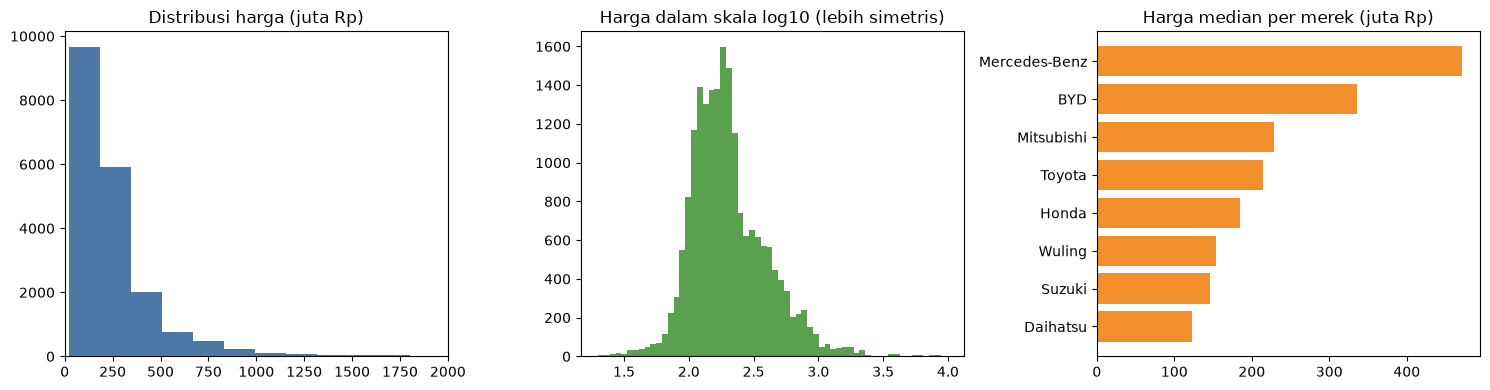

In [130]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(df["harga"] / 1e6, bins=60, color="#4c78a8")
ax[0].set_title("Distribusi harga (juta Rp)")
ax[0].set_xlim(0, 2000)

ax[1].hist(np.log10(df["harga"] / 1e6), bins=60, color="#59a14f")
ax[1].set_title("Harga dalam skala log10 (lebih simetris)")

med = df.groupby("merek")["harga"].median().sort_values() / 1e6
med = med[df["merek"].value_counts()[med.index] >= 50]
ax[2].barh(med.index, med.values, color="#f28e2b")
ax[2].set_title("Harga median per merek (juta Rp)")

plt.tight_layout()
plt.show()

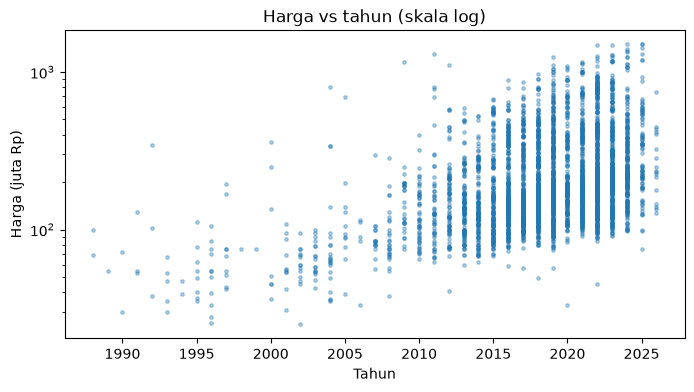

Median harga per kelompok bahan bakar (juta Rp):
bahan_bakar
Bensin    175.0
Diesel    375.0
Hybrid    280.0
Listrik   280.0


In [131]:
sampel = df[df["harga"] < 1.5e9].sample(4000, random_state=0)
plt.figure(figsize=(8, 4))
plt.scatter(sampel["tahun"], sampel["harga"] / 1e6, s=6, alpha=0.35)
plt.yscale("log")
plt.title("Harga vs tahun (skala log)")
plt.xlabel("Tahun")
plt.ylabel("Harga (juta Rp)")
plt.show()

print("Median harga per kelompok bahan bakar (juta Rp):")
print((df.groupby("bahan_bakar")["harga"].median() / 1e6).round(0).to_string())

# Fitur
#####
- `umur` = 2026 dikurangi tahun mobil.
- `model_g` = merek + model. Model dengan data sedikit (< 8 iklan) digabung jadi `"<merek> LAINNYA"` supaya model tidak menghafal.
- Model dilatih pada **semua iklan**, termasuk yang km-nya kosong (pohon keputusan bisa menangani nilai kosong). Kalau hanya iklan ber-km yang dipakai, Mitsubishi, Wuling, dan BYD hampir hilang dari data karena batch 2026 jarang mencantumkan km.
- Karena app meminta km dari penjual, hasil dilaporkan **dua kali**: semua iklan, dan hanya iklan yang km-nya diketahui (situasi app yang sebenarnya).
- Merek dengan kurang dari 50 iklan dikeluarkan dan app akan menolaknya dengan jujur.

In [132]:
TAHUN_ACUAN = 2026
TAHUN_DATA = {"OLX": 2026, "Mobil123": 2026, "Carsome": 2023} 
SUMBER_PREDIKSI = "OLX"
MIN_MEREK = 15     
MEREK_KECIL = 50    
MIN_MODEL = 8       

data = df[df["bahan_bakar"].notna()].copy()
jumlah_merek = data["merek"].value_counts()
MEREK_DIDUKUNG = sorted(jumlah_merek[jumlah_merek >= MIN_MEREK].index)
data = data[data["merek"].isin(MEREK_DIDUKUNG)].copy()
ADA_KM = data["km"].notna().values   # penanda: iklan yang km-nya diketahui

data["umur"] = (data["sumber"].map(TAHUN_DATA) - data["tahun"]).clip(lower=0)
data["model_lengkap"] = data["merek"] + " " + data["model"].astype(str)
jumlah_model = data["model_lengkap"].value_counts()
MODEL_DIKENAL = set(jumlah_model[jumlah_model >= MIN_MODEL].index)
data["model_g"] = np.where(data["model_lengkap"].isin(MODEL_DIKENAL),
                           data["model_lengkap"], data["merek"] + " LAINNYA")

JUMLAH_MEREK = data["merek"].value_counts()

FITUR_KAT = ["merek", "model_g", "bahan_bakar", "bodi", "transmisi", "sumber"]
FITUR_NUM = ["umur", "km", "mesin_l"]
X = data[FITUR_KAT + FITUR_NUM]
y = data["harga"]

print("Baris untuk model:", len(data), "| yang km-nya diketahui:", int(ADA_KM.sum()))
print("Merek didukung:", MEREK_DIDUKUNG)
print("Merek berdata sedikit (keyakinan Rendah):", [m for m in MEREK_DIDUKUNG if JUMLAH_MEREK[m] < MEREK_KECIL])
print("Model dikenal (>= %d iklan): %d" % (MIN_MODEL, len(MODEL_DIKENAL)))

Baris untuk model: 19472 | yang km-nya diketahui: 10309
Merek didukung: ['BYD', 'Daihatsu', 'Honda', 'Mazda', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'Suzuki', 'Toyota', 'Wuling']
Merek berdata sedikit (keyakinan Rendah): ['Mazda', 'Nissan']
Model dikenal (>= 8 iklan): 125


# Fungsi bantu bangun model

In [133]:
def model_pohon(kat, loss="squared_error", quantile=None):
    pre = ColumnTransformer(
        [("kat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), kat)],
        remainder="passthrough")
    reg = HistGradientBoostingRegressor(
        loss=loss, quantile=quantile, max_iter=400, learning_rate=0.06,
        categorical_features=list(range(len(kat))), random_state=0)
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("reg", reg)]),
                                      func=np.log, inverse_func=np.exp)


def model_ridge(kat, num):
    pre = ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore"), kat),
        ("num", Pipeline([("isi", SimpleImputer(strategy="median")), ("skala", StandardScaler())]), num)])
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("reg", Ridge(alpha=3.0))]),
                                      func=np.log, inverse_func=np.exp)


def skor(asli, pred):
    ape = np.abs(pred - asli) / asli
    return {"MAE (juta Rp)": np.mean(np.abs(pred - asli)) / 1e6,
            "MAPE (%)": ape.mean() * 100,
            "Median error (%)": np.median(ape) * 100}

# Bandingkan antar model 

In [134]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
kandidat = {
    "Tebak median (pembanding)": DummyRegressor(strategy="median"),
    "Ridge (linear)": model_ridge(FITUR_KAT, FITUR_NUM),
    "Gradient Boosting (pohon)": model_pohon(FITUR_KAT),
}
hasil, pred_cv = {}, {}
for nama, m in kandidat.items():
    pred_cv[nama] = cross_val_predict(m, X, y, cv=kf)
    hasil[nama] = skor(y.values, pred_cv[nama])
tabel_a = pd.DataFrame(hasil).T
print("Semua iklan:")
display(tabel_a)
print("Hanya iklan yang km-nya diketahui (situasi di app):")
pd.DataFrame({n: skor(y.values[ADA_KM], p[ADA_KM]) for n, p in pred_cv.items()}).T

Semua iklan:


,MAE (juta Rp),MAPE (%),Median error (%)
Tebak median (pembanding),147.2,49.1,40.8
Ridge (linear),47.0,14.3,9.4
Gradient Boosting (pohon),31.0,10.1,6.5


Hanya iklan yang km-nya diketahui (situasi di app):


,MAE (juta Rp),MAPE (%),Median error (%)
Tebak median (pembanding),114.2,40.1,34.2
Ridge (linear),34.3,11.6,8.5
Gradient Boosting (pohon),21.9,7.9,5.6


# Uji : bagaimana jika model belum pernah melihat object sama sekali(kurang data)

In [135]:
kat_tanpa_model = [k for k in FITUR_KAT if k != "model_g"]
m_baru = model_pohon(kat_tanpa_model)
pred_baru = cross_val_predict(m_baru, X[kat_tanpa_model + FITUR_NUM], y,
                              cv=GroupKFold(n_splits=5), groups=data["model_g"])
p_dikenal = pred_cv["Gradient Boosting (pohon)"]
skor_baru = skor(y.values, pred_baru)

tabel_b = pd.DataFrame({
    "Model dikenal, km diketahui": skor(y.values[ADA_KM], p_dikenal[ADA_KM]),
    "Model dikenal, semua iklan": skor(y.values, p_dikenal),
    "Model baru, km diketahui": skor(y.values[ADA_KM], pred_baru[ADA_KM]),
    "Model baru, semua iklan": skor_baru,
}).T
tabel_b

,MAE (juta Rp),MAPE (%),Median error (%)
"Model dikenal, km diketahui",21.9,7.9,5.6
"Model dikenal, semua iklan",31.0,10.1,6.5
"Model baru, km diketahui",60.9,21.0,15.3
"Model baru, semua iklan",79.7,24.4,16.9


In [136]:
# Seberapa meleset per merek dan per rentang harga (skenario model dikenal)
cek = data[["merek", "harga"]].copy()
cek["error_%"] = np.abs(pred_cv["Gradient Boosting (pohon)"] - y.values) / y.values * 100
cek["pita_harga"] = pd.cut(cek["harga"] / 1e6, [0, 150, 300, 600, 1000, 1e6],
                           labels=["< 150 jt", "150-300 jt", "300-600 jt", "600 jt - 1 M", "> 1 M"])
print("Rata-rata error (%) per merek:")
print(cek.groupby("merek")["error_%"].agg(jumlah="size", MAPE="mean").sort_values("jumlah", ascending=False).to_string())
print("\nRata-rata error (%) per rentang harga:")
print(cek.groupby("pita_harga")["error_%"].agg(jumlah="size", MAPE="mean").to_string())

Rata-rata error (%) per merek:
               jumlah  MAPE
merek                      
Honda            4894   8.2
Toyota           3811   9.1
Daihatsu         3580   8.3
Mercedes-Benz    2997  17.1
Suzuki           2976   9.4
Mitsubishi        502  12.6
Wuling            433  10.1
BYD               226   6.3
Nissan             33  14.4
Mazda              20   9.4

Rata-rata error (%) per rentang harga:
              jumlah  MAPE
pita_harga                
< 150 jt        7029  11.4
150-300 jt      7765   8.3
300-600 jt      3344  10.3
600 jt - 1 M     917  12.5
> 1 M            417  15.4


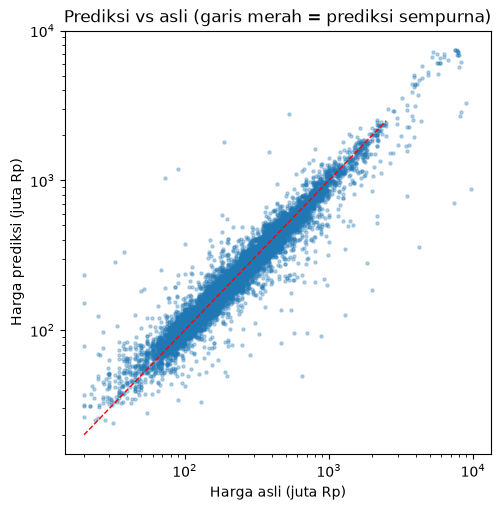

In [137]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y / 1e6, pred_cv["Gradient Boosting (pohon)"] / 1e6, s=5, alpha=0.3)
batas = [20, 2500]
plt.plot(batas, batas, "r--", lw=1)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Harga asli (juta Rp)"); plt.ylabel("Harga prediksi (juta Rp)")
plt.title("Prediksi vs asli (garis merah = prediksi sempurna)")
plt.show()

### Apakah menambahkan dan menggabungkan dataset carsome membantu model

In [138]:
adalah_carsome = (data["sumber"] == "Carsome").values
idx_z, idx_c = np.where(~adalah_carsome)[0], np.where(adalah_carsome)[0]
kf2 = KFold(n_splits=5, shuffle=True, random_state=0)
p_tanpa, p_dengan = np.zeros(len(data)), np.zeros(len(data))

for (ztr, zte), (ctr, cte) in zip(kf2.split(idx_z), kf2.split(idx_c)):
    latih_z, uji_idx = idx_z[ztr], np.r_[idx_z[zte], idx_c[cte]]
    latih_gabung = np.r_[latih_z, idx_c[ctr]]
    m_tanpa = model_pohon(FITUR_KAT).fit(X.iloc[latih_z], y.iloc[latih_z])
    m_dengan = model_pohon(FITUR_KAT).fit(X.iloc[latih_gabung], y.iloc[latih_gabung])
    p_tanpa[uji_idx] = m_tanpa.predict(X.iloc[uji_idx])
    p_dengan[uji_idx] = m_dengan.predict(X.iloc[uji_idx])

tabel_c = pd.DataFrame({
    "Uji di data OLX/Mobil123, tanpa Carsome": skor(y.values[~adalah_carsome], p_tanpa[~adalah_carsome]),
    "Uji di data OLX/Mobil123, dengan Carsome": skor(y.values[~adalah_carsome], p_dengan[~adalah_carsome]),
    "Uji di data Carsome, tanpa Carsome": skor(y.values[adalah_carsome], p_tanpa[adalah_carsome]),
    "Uji di data Carsome, dengan Carsome": skor(y.values[adalah_carsome], p_dengan[adalah_carsome]),
}).T
display(tabel_c)

cek_c = data.loc[adalah_carsome, ["merek"]].copy()
cek_c["error_%"] = np.abs(p_dengan[adalah_carsome] - y.values[adalah_carsome]) / y.values[adalah_carsome] * 100
print("\nError (%) per merek di data Carsome, model gabungan:")
cek_c.groupby("merek")["error_%"].agg(jumlah="size", MAPE="mean").sort_values("jumlah", ascending=False)

,MAE (juta Rp),MAPE (%),Median error (%)
"Uji di data OLX/Mobil123, tanpa Carsome",31.1,10.2,6.5
"Uji di data OLX/Mobil123, dengan Carsome",31.3,10.2,6.5
"Uji di data Carsome, tanpa Carsome",13.4,7.1,4.6
"Uji di data Carsome, dengan Carsome",11.4,6.0,3.9



Error (%) per merek di data Carsome, model gabungan:


,jumlah,MAPE
merek,,
Toyota,171,5.2
Honda,145,5.4
Daihatsu,82,3.8
Mitsubishi,63,5.3
Suzuki,62,6.0
Nissan,33,14.2
Wuling,24,8.9
Mazda,19,10.8


# Fitur paling berpengaruh

Skor di data uji terpisah: {'MAE (juta Rp)': np.float64(31.8), 'MAPE (%)': np.float64(10.0), 'Median error (%)': np.float64(6.4)}


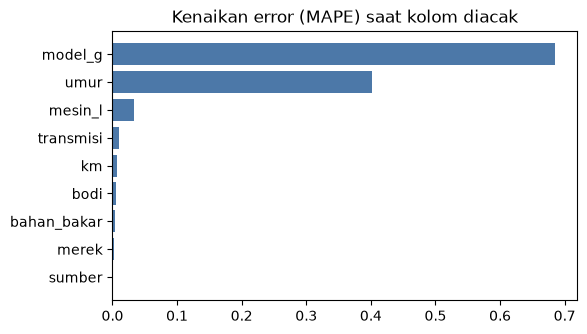

In [139]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=1)
uji = model_pohon(FITUR_KAT).fit(X_tr, y_tr)
print("Skor di data uji terpisah:", {k: round(v, 1) for k, v in skor(y_te.values, uji.predict(X_te)).items()})

pi = permutation_importance(uji, X_te, y_te, n_repeats=5, random_state=0,
                            scoring="neg_mean_absolute_percentage_error")
penting = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(6, 3.5))
plt.barh(penting.index, penting.values, color="#4c78a8")
plt.title("Kenaikan error (MAPE) saat kolom diacak")
plt.show()

# Latih Model final

In [140]:
final_est = model_pohon(FITUR_KAT).fit(X, y)

# Faktor rentang per tingkat keyakinan, dari sisa error data uji (validasi silang)
n_model = data["model_lengkap"].map(jumlah_model).values
tingkat = np.where(n_model >= 30, "Tinggi", np.where(n_model >= MIN_MODEL, "Sedang", "Rendah"))
n_merek = data["merek"].map(JUMLAH_MEREK).values
tingkat = np.where(n_merek < MEREK_KECIL, "Rendah", tingkat)   # merek berdata sedikit: selalu Rendah
sisa = np.log(y.values / pred_cv["Gradient Boosting (pohon)"])
FAKTOR = {t: (float(np.exp(np.quantile(sisa[tingkat == t], 0.10))),
              float(np.exp(np.quantile(sisa[tingkat == t], 0.90))))
          for t in ["Tinggi", "Sedang", "Rendah"]}
for t, (a, b) in FAKTOR.items():
    print(f"Keyakinan {t:7s} ({(tingkat == t).sum():5d} iklan): rentang = estimasi x {a:.2f} sampai x {b:.2f}")

# Untuk menghitung "tingkat keyakinan" di app
info = {
    "tahun_acuan": TAHUN_ACUAN,
    "sumber_prediksi": SUMBER_PREDIKSI,
    "jumlah_per_merek": JUMLAH_MEREK.to_dict(),
    "merek_kecil": MEREK_KECIL,
    "merek_didukung": MEREK_DIDUKUNG,
    "jumlah_per_model": jumlah_model.to_dict(),
    "model_dikenal": sorted(MODEL_DIKENAL),
    "min_model": MIN_MODEL,
    "faktor_rentang": FAKTOR,
    "fitur_kat": FITUR_KAT,
    "fitur_num": FITUR_NUM,
    "pilihan": {
        "bahan_bakar": sorted(data["bahan_bakar"].dropna().unique()),
        "bodi": sorted(data["bodi"].dropna().unique()),
        "transmisi": sorted(data["transmisi"].dropna().unique()),
    },
    "model_per_merek": {m: sorted(g["model"].astype(str).unique()) for m, g in data.groupby("merek")},
    "skor_cv": tabel_b.round(2).to_dict(orient="index"),
    "skor_gabungan": tabel_c.round(2).to_dict(orient="index"),
}
joblib.dump({"est": final_est, "info": info}, PATH_MODEL)
print("Tersimpan:", PATH_MODEL)

Keyakinan Tinggi  (18465 iklan): rentang = estimasi x 0.87 sampai x 1.14
Keyakinan Sedang  (  614 iklan): rentang = estimasi x 0.76 sampai x 1.26
Keyakinan Rendah  (  393 iklan): rentang = estimasi x 0.64 sampai x 1.64
Tersimpan: ../models/model_v2.joblib


# Fungsi Prediksi

##### Tingkat keyakinan:
- **Tinggi**: model punya >= 30 iklan di data.
- **Sedang**: model punya 8-29 iklan.
- **Rendah**: merek dikenal, tapi model jarang/belum ada. Estimasi kasar.
- **Tidak didukung**: merek tidak ada di data. Tidak ada angka yang diberikan.

In [141]:
def prediksi(merek, model, tahun, km, mesin_l, bahan_bakar, bodi, transmisi, paket=None):
    paket = paket or joblib.load(PATH_MODEL)
    info = paket["info"]
    if merek not in info["merek_didukung"]:
        return {"keyakinan": "Tidak didukung",
                "catatan": f"Merek {merek} belum ada di data. Merek yang didukung: {', '.join(info['merek_didukung'])}."}
    lengkap = f"{merek} {model}"
    n = info["jumlah_per_model"].get(lengkap, 0)
    model_g = lengkap if lengkap in info["model_dikenal"] else f"{merek} LAINNYA"
    keyakinan = "Tinggi" if n >= 30 else "Sedang" if n >= info["min_model"] else "Rendah"
    if info["jumlah_per_merek"][merek] < info["merek_kecil"]:
        keyakinan = "Rendah"
    baris = pd.DataFrame([{
        "merek": merek, "model_g": model_g, "bahan_bakar": bahan_bakar, "bodi": bodi,
        "transmisi": transmisi, "sumber": info["sumber_prediksi"],
        "umur": max(info["tahun_acuan"] - tahun, 0),
        "km": km, "mesin_l": 0.0 if bahan_bakar == "Listrik" else mesin_l}])
    est = paket["est"].predict(baris)[0]
    f_low, f_high = info["faktor_rentang"][keyakinan]
    return {"estimasi": est, "rendah": est * f_low, "tinggi": est * f_high, "keyakinan": keyakinan, "jumlah_data_model": n}


def rp(x):
    return f"Rp {x/1e6:,.0f} juta"


paket = joblib.load(PATH_MODEL)
contoh = prediksi("Toyota", "Avanza", 2018, 60000, 1.3, "Bensin", "MPV", "Manual", paket)
contoh

{'estimasi': np.float64(135111443.44437242),
 'rendah': np.float64(118014243.98009533),
 'tinggi': np.float64(153554970.71941984),
 'keyakinan': 'Tinggi',
 'jumlah_data_model': 458}

In [142]:
paket["info"]["model_per_merek"]["Toyota"][:15]

['86',
 'Agya',
 'Alphard',
 'Altis',
 'Avanza',
 'BZ4X',
 'C-HR',
 'Calya',
 'Camry',
 'Corolla',
 'Corolla Altis',
 'Corolla Cross',
 'Crown',
 'Crown Royal',
 'Dyna']

In [143]:
hasil_tes = prediksi("Honda", "Brio", 2020, 40000, 1.2, "Bensin", "Hatchback", "Automatic", paket)
if "estimasi" in hasil_tes:
    print(f"Estimasi : {rp(hasil_tes['estimasi'])}")
    print(f"Rentang  : {rp(hasil_tes['rendah'])}  sampai  {rp(hasil_tes['tinggi'])}")
print("Keyakinan:", hasil_tes["keyakinan"], "| data model ini:", hasil_tes.get("jumlah_data_model"))

print()
byd = paket["info"]["model_per_merek"]["BYD"][0]
print("Contoh mobil listrik:", byd)
h = prediksi("BYD", byd, 2024, 20000, 0.0, "Listrik", "SUV", "Automatic", paket)
print(f"Estimasi {rp(h['estimasi'])} (rentang {rp(h['rendah'])} - {rp(h['tinggi'])}), keyakinan {h['keyakinan']}")

print()
n = prediksi("Nissan", "Grand Livina", 2015, 90000, 1.5, "Bensin", "MPV", "Automatic", paket)
print(f"Contoh merek berdata sedikit (Nissan): estimasi {rp(n['estimasi'])} (rentang {rp(n['rendah'])} - {rp(n['tinggi'])}), keyakinan {n['keyakinan']}")

print()
print(prediksi("BMW", "320i", 2015, 90000, 2.0, "Bensin", "Sedan", "Automatic", paket))

Estimasi : Rp 152 juta
Rentang  : Rp 133 juta  sampai  Rp 172 juta
Keyakinan: Tinggi | data model ini: 635

Contoh mobil listrik: Atto 1
Estimasi Rp 208 juta (rentang Rp 182 juta - Rp 236 juta), keyakinan Tinggi

Contoh merek berdata sedikit (Nissan): estimasi Rp 105 juta (rentang Rp 68 juta - Rp 173 juta), keyakinan Rendah

{'keyakinan': 'Tidak didukung', 'catatan': 'Merek BMW belum ada di data. Merek yang didukung: BYD, Daihatsu, Honda, Mazda, Mercedes-Benz, Mitsubishi, Nissan, Suzuki, Toyota, Wuling.'}
